# Basic Usage of Diffraction Package

This notebook demonstrates the basic functionality of the diffraction package for X-ray diffraction calculations.

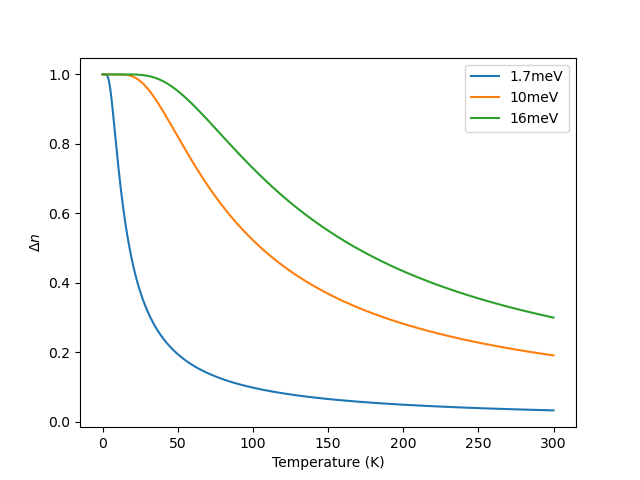

In [36]:
%matplotlib widget

import numpy as np
import pylab as plt

def boltzmann(dE, T):
    return np.tanh(dE/(2*8.617333262e-5*T))

T = np.arange(0,300,0.1)
plt.close("boltzmann")
plt.figure("boltzmann")
plt.plot(T, boltzmann(1.7e-3, T), label = "1.7meV")
plt.plot(T, boltzmann(10e-3, T), label = "10meV")
plt.plot(T, boltzmann(16e-3, T), label = "16meV")

plt.xlabel("Temperature (K)")
plt.ylabel(r"$\Delta n$")
plt.legend()

In [1]:
cd ..

/Users/hello/switchdrive/python/claude/diffraction


In [17]:
from diffraction import Crystal

# Load a crystal from CIF file
crystal = Crystal.from_cif("Tb2Ti2O7", "diffraction/data/Tb2Ti2O7.cif")

# Set orientation relative to laboratory space and calc UB matrix
crystal.add_orientation((0,0,1), (0,0,1), "normal", frame="diffcalc")
crystal.add_orientation((-1,1,0), (0,1,0), "inplane along beam", frame="diffcalc")
crystal.calc_ub()

# Set angular constraints
crystal.set_constraints(delta=0, phi=0, eta=0)

print(crystal)

### LATTICE ###
name  : Tb2Ti2O7
a     : 10.1584
b     : 10.1584
c     : 10.1584
alpha : 90
beta  : 90
gamma : 90

### UNIT CELL ###
0 (Tb3+ (65), ('16d', None), 1.01, 0.37)
1 (Ti4+ (22), ('16c', None), 1.0, 0.32)
2 (O2-. ( 8), ('48f', (np.float64(0.3282),)), 0.98, 0.3)
3 (O2-. ( 8), ('8b', None), 0.97, 0.16)

### ORIENTATIONS ###
hkl            xyz            tag
(0, 0, 1)      (0, 0, 1)      normal
(-1, 1, 0)     (0, 1, 0)      inplane along beam

### CONSTRAINTS ###
eta   : 0
phi   : 0
delta : 0



In [22]:
hkl = (0,0.001,2)
crystal.calc_angles(hkl, energy=1238.4, pandas=True)

,mu,delta,gamma,eta,chi,phi,theta,ttheta,qaz,alpha,naz,tau,psi,beta,betain,betaout
sol. 0,260.228827,0.0,160.498169,0.0,179.979743,0.0,80.249085,160.498169,0.0,-6.878213,-45.416866,90.0,44.999996,6.878213,80.228807,80.269321
sol. 1,80.269342,0.0,160.498169,0.0,-0.020257,0.0,80.249085,160.498169,0.0,6.878213,134.583134,90.0,-135.000004,-6.878213,80.269321,80.228807
sol. 2,-80.269342,0.0,-160.498169,0.0,179.979743,0.0,80.249085,160.498169,180.0,6.878213,-45.416866,90.0,-135.000004,-6.878213,80.269321,80.228807
sol. 3,-260.228827,0.0,-160.498169,0.0,-0.020257,0.0,80.249085,160.498169,180.0,-6.878213,134.583134,90.0,44.999996,6.878213,80.228807,80.269321


In [23]:
crystal.calc_angles(hkl, energy=1275, pandas=True)

,mu,delta,gamma,eta,chi,phi,theta,ttheta,qaz,alpha,naz,tau,psi,beta,betain,betaout
sol. 0,253.168383,0.0,146.377281,0.0,179.979743,0.0,73.18864,146.377281,0.0,-11.800849,-46.25088,90.0,44.999996,11.800849,73.168371,73.208886
sol. 1,73.208897,0.0,146.377281,0.0,-0.020257,0.0,73.18864,146.377281,0.0,11.800849,133.74912,90.0,-135.000004,-11.800849,73.208886,73.168371
sol. 2,-73.208897,0.0,-146.377281,0.0,179.979743,0.0,73.18864,146.377281,180.0,11.800849,-46.25088,90.0,-135.000004,-11.800849,73.208886,73.168371
sol. 3,-253.168383,0.0,-146.377281,0.0,-0.020257,0.0,73.18864,146.377281,180.0,-11.800849,133.74912,90.0,44.999996,11.800849,73.168371,73.208886


In [10]:
160.498169-146.377281

14.12088799999998

In [16]:
hkl = (0,2.000,0.001)
print(str(crystal.calc_angles(hkl, energy=8000, pandas=False)[4][0]))
pos = crystal.calc_angles(hkl, energy=8000, pandas=False)[4][0]

IndexError: list index out of range

In [34]:
crystal.add_reflection(hkl, pos, 8000)

In [3]:
# Calculate diffractometer angles for a reflection
angles = crystal.calc_angles((0, 0, 1), 8048.0)
print(angles)

                mu  delta      gamma  eta    chi  phi      theta     ttheta  \
sol. 0  191.259224    0.0  22.518447  0.0  180.0  0.0  11.259224  22.518447   
sol. 1   11.259224    0.0  22.518447  0.0    0.0  0.0  11.259224  22.518447   
sol. 2  -11.259224    0.0 -22.518447  0.0  180.0  0.0  11.259224  22.518447   
sol. 3 -191.259224    0.0 -22.518447  0.0    0.0  0.0  11.259224  22.518447   

          qaz      alpha           naz   tau           psi       beta  \
sol. 0    0.0  78.740776  1.800000e+02  90.0 -1.800000e+02 -78.740776   
sol. 1    0.0 -78.740776  1.773450e-46  90.0 -3.462630e-47  78.740776   
sol. 2  180.0 -78.740776  1.800000e+02  90.0  0.000000e+00  78.740776   
sol. 3  180.0  78.740776  1.773450e-46  90.0  1.800000e+02 -78.740776   

           betain    betaout  
sol. 0  11.259224  11.259224  
sol. 1  11.259224  11.259224  
sol. 2  11.259224  11.259224  
sol. 3  11.259224  11.259224  


In [4]:
# Calculate structure factor
F = crystal.calc_structure_factor((0, 0, 1), 8048.0)
print(f"Structure factor F(001) = {F}")

Structure factor F(001) = (7.291157631497841+0.0077356228806806995j)


## Visualization

### Show the unit cell

In [5]:
vis = crystal.show_unit_cell(browser = "notebook")

### Load previously saved crystal

In [34]:
crystal2 = Crystal.load("LiNbO3")

In [50]:
vis2 = crystal2.show_unit_cell(browser = "notebook")


In [56]:
vis2.env.set_camera_pose((0.5,2,0.5),(0,0.,1))

### Animate atoms along a linear combination of two displacement vectors

In [6]:
import numpy as np

# Create exemplary displacement vectors along x and y directions

displacement_vector_x = {
    "Sr1": [0.01, 0, 0],
    "Ti1": [0.03, 0, 0],
    "O1": [-0.1, 0, 0],
    "O2": [-0.1, 0, 0],
    "O3": [-0.1, 0, 0],
}

vector_x = [] # Take care of multiplicity
for (atom, displacement), mult in zip(displacement_vector_x.items(), vis.multiplicity):
    for n in range(mult):
        vector_x.append(displacement)
vector_x = np.array(vector_x)

displacement_vector_y = {
    "Sr1": [0, 0.01, 0],
    "Ti1": [0, 0.03, 0],
    "O1": [0, -0.1, 0],
    "O2": [0, -0.1, 0],
    "O3": [0, -0.1, 0],
}

vector_y = [] # Take care of multiplicity
for (atom, displacement), mult in zip(displacement_vector_y.items(), vis.multiplicity):
    for n in range(mult):
        vector_y.append(displacement)
vector_y = np.array(vector_y)

In [7]:
# Create exemplary displacement amplitudes
n = np.linspace(0,20*np.pi,500)
amplitudes = 0.5* np.array([np.sin(n), np.cos(n)])

In [9]:
# Start animation
vis = crystal.show_unit_cell(browser="notebook")
vis.animate(vectors=[vector_x, vector_y], amplitudes=amplitudes, dt=0.01, scale=1)

Sr1_0 [0. 0. 0.]
Sr1_1 [0.   0.   3.95]
Sr1_2 [0.   3.95 0.  ]
Sr1_3 [0.   3.95 3.95]
Sr1_4 [3.95 0.   0.  ]
Sr1_5 [3.95 0.   3.95]
Sr1_6 [3.95 3.95 0.  ]
Sr1_7 [3.95 3.95 3.95]
Ti1_0 [1.97 1.97 1.97]
O1_0 [1.97 0.   1.97]
O1_1 [1.97 3.95 1.97]
O2_0 [1.97 1.97 0.  ]
O2_1 [1.97 1.97 3.95]
O3_0 [0.   1.97 1.97]
O3_1 [3.95 1.97 1.97]


### Plot constraint sensitivity of diffraction angles
- Calculate the sensitivty of the diffraction angle sweeping one of the constraints

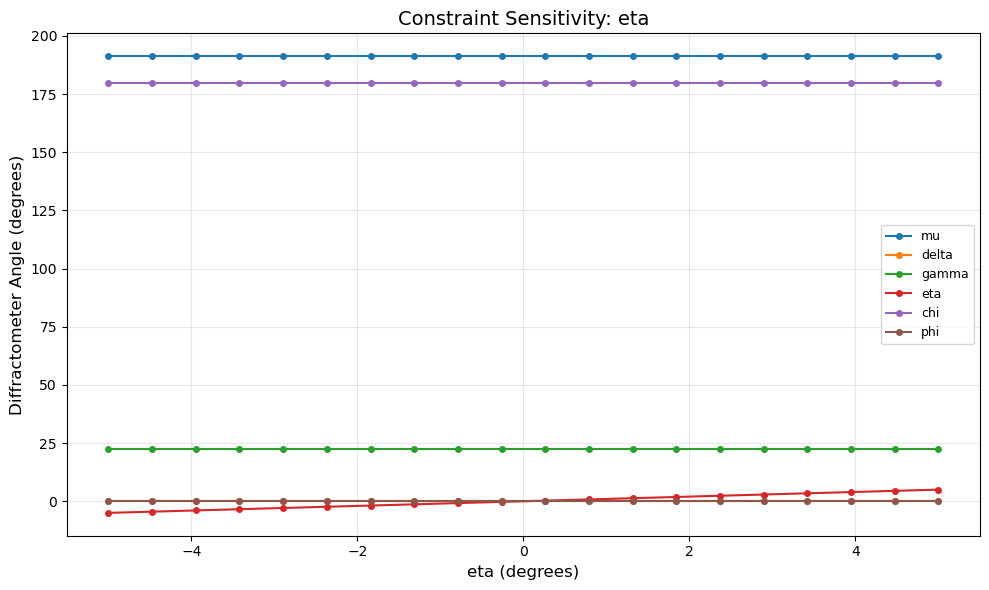

In [5]:
import diffraction.visualization as vis
fig, ax, x_values, results = vis.angular_solutions.plot_constraint_sensitivity(crystal, (0,0,1), 8000, 0, "eta",  -5,5)